# **ETIQUETADO GRAMATICAL CON BERT**

## **Tarea de Sequence Labeling**

Se realiza el ajuste fino de BERT (Un modelo con arquitectura decoder) para asignar una categoría gramatical a cada palabra de una oración en inglés. La base de datos utilizada contiene 16622 oraciones ya repartidas entre entrenamiento, validación y prueba.

La base de datos tiene 17 categorias gramaticales posibles, cada palabra en cada oración ya viene etiquetada y es lo que se utilizará para el entrenamiento del modelo.

Por limitantes de tiempo y recursos, el entrenamiento se hará con un límite de entrenamiento de 3h para el entorno con GPU T4, una vez transcurridas las 3 horas el entorno seleccionará los mejores hiperparametros entrenados hasta el momento.

**Objetivo y descripción de la BD**


La base de datos es [**English Web Treebank**](https://huggingface.co/datasets/universal-dependencies/universal_dependencies), disponible en hugging face. Se toma la configuración en_ewt de la revisión 2.18 en Hugging Face. Contiene oraciones en inglés de distintos géneros web, como emails, blogs y reseñas.

Las categorias gramaticales están puestas en upos por cada palabra de cada oración, y el sent_id identifica cada oración.

La entrada es una oración como lista de palabras. La salida es una secuencia de etiquetas UPOS, una para cada palabra y en el mismo orden. Esto es *sequence labeling*.

La utilidad está en identificar categorías según el contexto. Esto podría permitir por ejemplo, categorizar cuando una misma palabra se utiliza como verbo o sustantivo, como pueden ser "book" y "milk", que ambas funcionan tanto como sustantivo como verbo.

# **INSTALACIONES E IMPORTACIONES**


In [1]:
!pip install -q transformers==4.57.1
!pip install -q accelerate==1.11.0
!pip install -q datasets==4.3.0
!pip install -q scikit-learn
!pip install -q matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.9.0 which is incompatible.


In [2]:
from collections import Counter
from hashlib import sha256
from importlib.metadata import version
from itertools import product
from pathlib import Path
from time import perf_counter

import gc
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from datasets import Dataset, load_dataset
from huggingface_hub import HfApi
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, f1_score
from transformers import (
    AutoTokenizer, BertForTokenClassification, DataCollatorForTokenClassification,
    EvalPrediction, Trainer, TrainingArguments, set_seed,
)
from transformers.trainer_utils import get_last_checkpoint


# **CONSTANTES**


In [3]:
DATASET_ID = "universal-dependencies/universal_dependencies"
DATASET_CONFIG = "en_ewt"
DATASET_REVISION = "2.18"
MODEL_ID = "google-bert/bert-base-cased"
MODEL_REVISION = "main"
OUTPUT_ROUTE = "BERT_Sequence_Labeling"

SEED = 42
MAX_LENGTH = 256
IGNORE_INDEX = -100
N_EXAMPLES = 3
N_SEARCH_SENTENCES = 8000
GRID_HOURS = 3.0
EVAL_BATCH_SIZE = 32

LEARNING_RATES = [1e-5, 2e-5, 3e-5, 5e-5]
WEIGHT_DECAYS = [0.0, 0.01, 0.05]
TRAIN_EPOCHS = [2, 3, 4, 5]
BATCH_SIZES = [8, 16]
WARMUP_RATIOS = [0.03, 0.10]
GRID_COLUMNS = ["learning_rate", "weight_decay", "num_train_epochs", "batch_size", "warmup_ratio"]

ID_TO_LABEL = dict(enumerate((
    "ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM",
    "PART", "PRON", "PROPN", "PUNCT", "SCONJ", "SYM", "VERB", "X",
)))
LABEL_TO_ID = {label: index for index, label in ID_TO_LABEL.items()}


# **CONFIGURACIONES**


In [4]:
set_seed(SEED)
output_path = Path(OUTPUT_ROUTE)
output_path.mkdir(parents = True, exist_ok = True)

use_cuda = torch.cuda.is_available()
use_bf16 = use_cuda and torch.cuda.get_device_capability()[0] >= 8 and torch.cuda.is_bf16_supported()
precision = "bf16" if use_bf16 else "fp16" if use_cuda else "fp32"
gpu_name = torch.cuda.get_device_name(0) if use_cuda else "CPU"
package_versions = {name: version(name) for name in ["transformers", "datasets", "accelerate", "torch"]}

print("Dispositivo:", gpu_name)
print("Precisión:", precision)


Dispositivo: Tesla T4
Precisión: fp16


# LECTURA DE DATOS


In [5]:
hub = HfApi()
dataset_revision = hub.dataset_info(DATASET_ID, revision = DATASET_REVISION).sha
model_revision = hub.model_info(MODEL_ID, revision = MODEL_REVISION).sha
raw_data = load_dataset(DATASET_ID, DATASET_CONFIG, revision = dataset_revision)
validation_split = "dev" if "dev" in raw_data else "validation"
source_splits = {"train": "train", "validation": validation_split, "test": "test"}

display(pd.DataFrame([
    {"partición": name, "oraciones": len(raw_data[split_name])}
    for name, split_name in source_splits.items()
]))


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

parquet/en_ewt/dev.parquet:   0%|          | 0.00/516k [00:00<?, ?B/s]

parquet/en_ewt/test.parquet:   0%|          | 0.00/523k [00:00<?, ?B/s]

parquet/en_ewt/train.parquet:   0%|          | 0.00/3.60M [00:00<?, ?B/s]

Generating dev split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

,partición,oraciones
0,train,12544
1,validation,2001
2,test,2077


# LIMPIEZA DE DATOS

Revisamos que cada oración tenga palabras y una etiqueta UPOS por palabra. Conservamos las particiones oficiales. La partición `dev` se usa como validación.


In [6]:
def valid_sentence(row: dict) -> bool:
    """Comprueba que las palabras y sus etiquetas estén alineadas."""
    words, tags = row["tokens"], row["upos"]
    return (
        bool(words) and bool(tags) and len(words) == len(tags)
        and all(isinstance(word, str) and word.strip() for word in words)
        and all(tag in LABEL_TO_ID for tag in tags)
    )


In [7]:
clean_data = {}
for name, split_name in source_splits.items():
    original = raw_data[split_name].select_columns(["sent_id", "tokens", "upos"])
    clean_data[name] = original.filter(valid_sentence)
    print(f"{name}: {len(clean_data[name])} válidas / {len(original)} originales")

train = clean_data["train"]


Filter:   0%|          | 0/12544 [00:00<?, ? examples/s]

train: 12544 válidas / 12544 originales


Filter:   0%|          | 0/2001 [00:00<?, ? examples/s]

validation: 2001 válidas / 2001 originales


Filter:   0%|          | 0/2077 [00:00<?, ? examples/s]

test: 2077 válidas / 2077 originales


# ANÁLISIS EXPLORATORIO

Revisamos las longitudes y la distribución de etiquetas en entrenamiento.


,palabras_por_oración
count,12544.000000
mean,16.308833
std,12.401967
min,1.000000
50%,14.000000
90%,32.000000
95%,39.000000
99%,57.000000
max,159.000000


,etiqueta,palabras,porcentaje
0,NOUN,34751,16.986675
1,PUNCT,23596,11.533987
2,VERB,22576,11.035400
3,PRON,18678,9.130014
4,ADP,17714,8.658800
5,DET,16299,7.967132
6,ADJ,13136,6.421023
7,AUX,12815,6.264114
8,PROPN,12620,6.168796
9,ADV,10172,4.972187


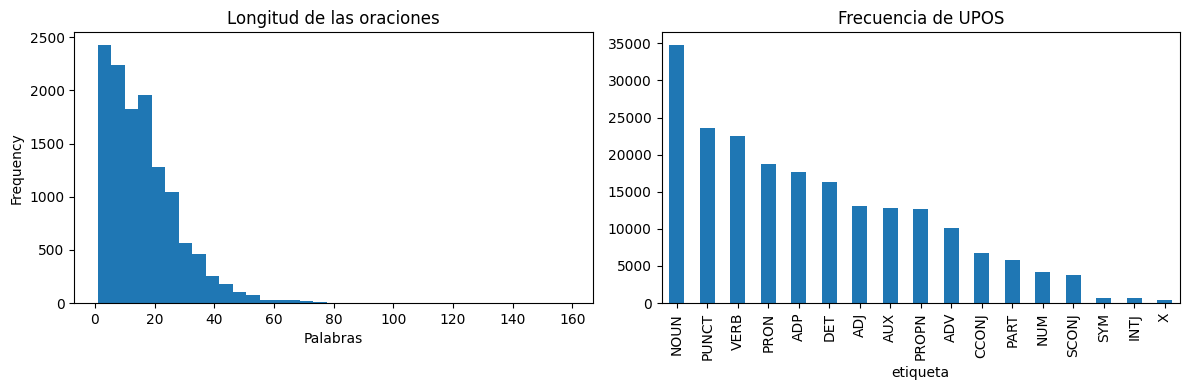

In [8]:
sentence_lengths = pd.Series([len(words) for words in train["tokens"]], name = "palabras_por_oración")
label_counts = Counter(tag for tags in train["upos"] for tag in tags)
label_distribution = pd.DataFrame(label_counts.most_common(), columns = ["etiqueta", "palabras"])
label_distribution["porcentaje"] = 100 * label_distribution["palabras"] / label_distribution["palabras"].sum()

display(sentence_lengths.describe(percentiles = [.50, .90, .95, .99]).to_frame())
display(label_distribution)
fig, axes = plt.subplots(1, 2, figsize = (12, 4))
sentence_lengths.plot.hist(bins = 35, ax = axes[0], title = "Longitud de las oraciones")
axes[0].set_xlabel("Palabras")
label_distribution.set_index("etiqueta")["palabras"].plot.bar(ax = axes[1], title = "Frecuencia de UPOS")
plt.tight_layout()
plt.show()


Hay un total de 17 categorias, puede haber un desbalance por aquellas que tienen una cantidad muy pequeña de datos, como X, INTJ y SYM que no superan los 1000.y no alcanzan el 1% de los datos.

**Ejemplos de oraciones etiquetadas en entrenamiento**


In [9]:
examples = train.shuffle(seed = SEED).select(range(min(N_EXAMPLES, len(train))))
for row in examples:
    print("Oración:", " ".join(row["tokens"]))
    display(pd.DataFrame({"Palabra": row["tokens"], "Etiqueta UPOS": row["upos"]}))


Oración: A key question is how they acquired the anthrax strain first isolated by the Texas Veterinary Medical Diagnostic Lab in 1980 .


,Palabra,Etiqueta UPOS
0,A,DET
1,key,ADJ
2,question,NOUN
3,is,AUX
4,how,ADV
5,they,PRON
6,acquired,VERB
7,the,DET
8,anthrax,NOUN
9,strain,NOUN


Oración: While it 's not easy to separate fact from fiction , Attorney General Ashcroft and Director Mueller have publicly confirmed Aafia is still being sought .


,Palabra,Etiqueta UPOS
0,While,SCONJ
1,it,PRON
2,'s,AUX
3,not,PART
4,easy,ADJ
5,to,PART
6,separate,VERB
7,fact,NOUN
8,from,ADP
9,fiction,NOUN


Oración: Kayani is well known and liked in Kabul as during the last year he led the Pakistani delegation in the tripartite military meetings with the Afghan and US military on issues related to border issues .


,Palabra,Etiqueta UPOS
0,Kayani,PROPN
1,is,AUX
2,well,ADV
3,known,VERB
4,and,CCONJ
5,liked,VERB
6,in,ADP
7,Kabul,PROPN
8,as,SCONJ
9,during,ADP


# PREPARACIÓN DEL TOKENIZADOR


In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision = model_revision, use_fast = True)
data_collator = DataCollatorForTokenClassification(
    tokenizer = tokenizer, label_pad_token_id = IGNORE_INDEX, pad_to_multiple_of = 8,
)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

# PREPARACIÓN PARA EL ENTRENAMIENTO

Medimos cada oración completa. Las oraciones que superan 256 subtokens, incluidos los especiales, o que pierden alguna palabra durante la tokenización quedan registradas y se excluyen. Cada oración usada conserva una etiqueta por palabra.


In [11]:
def tokenize_batch(batch: dict) -> dict:
    """Alinea las etiquetas UPOS con los primeros subtokens de BERT."""
    encoded = tokenizer(batch["tokens"], is_split_into_words = True, truncation = False, verbose = False)
    labels, covered = [], []

    for index, tags in enumerate(batch["upos"]):
        word_ids = encoded.word_ids(batch_index = index)
        seen = set()
        sentence_labels = []
        for word_id in word_ids:
            if word_id is None or word_id in seen:
                sentence_labels.append(IGNORE_INDEX)
            else:
                sentence_labels.append(LABEL_TO_ID[tags[word_id]])
                seen.add(word_id)
        labels.append(sentence_labels)
        covered.append(len(seen) == len(tags))

    encoded["labels"] = labels
    encoded["n_subwords"] = [len(ids) for ids in encoded["input_ids"]]
    encoded["all_words_covered"] = covered
    return encoded


def fits_model(row: dict) -> bool:
    """Identifica secuencias completas que caben en el presupuesto elegido."""
    return row["all_words_covered"] and row["n_subwords"] <= MAX_LENGTH


In [12]:
aligned_data, alignment_audit = {}, []
for name, data in clean_data.items():
    aligned = data.map(tokenize_batch, batched = True)
    eligible = aligned.filter(fits_model)
    aligned_data[name] = eligible.remove_columns(["all_words_covered", "n_subwords"])
    alignment_audit.append({
        "partición": name,
        "preparadas": len(eligible),
        "excluidas": len(aligned) - len(eligible),
        "sobre_el_límite": sum(length > MAX_LENGTH for length in aligned["n_subwords"]),
        "con_palabras_sin_alinear": sum(not covered for covered in aligned["all_words_covered"]),
    })

alignment_df = pd.DataFrame(alignment_audit)
display(alignment_df)


Map:   0%|          | 0/12544 [00:00<?, ? examples/s]

Filter:   0%|          | 0/12544 [00:00<?, ? examples/s]

Map:   0%|          | 0/2001 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2001 [00:00<?, ? examples/s]

Map:   0%|          | 0/2077 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2077 [00:00<?, ? examples/s]

,partición,preparadas,excluidas,sobre_el_límite,con_palabras_sin_alinear
0,train,12544,0,0,0
1,validation,2001,0,0,0
2,test,2076,1,1,0


# DEFINICIÓN DE LAS MÉTRICAS

Se compara una etiqueta por palabra. La exactitud mide el porcentaje de aciertos y el macro-F1 da a cada categoría el mismo peso. Se utiliza el macro-F1 de validación para elegir los hiperparámetros.


In [13]:
def reduce_logits(logits: torch.Tensor | tuple, labels: torch.Tensor) -> torch.Tensor:
    """Conserva solo el identificador de la etiqueta más probable."""
    if isinstance(logits, tuple):
        logits = logits[0]
    return logits.argmax(dim = -1)


def compute_metrics(prediction: EvalPrediction) -> dict:
    """Calcula exactitud y macro-F1 sobre las palabras etiquetadas."""
    mask = prediction.label_ids != IGNORE_INDEX
    actual = prediction.label_ids[mask]
    predicted = prediction.predictions[mask]
    return {
        "accuracy": float(accuracy_score(actual, predicted)),
        "macro_f1": float(f1_score(actual, predicted, labels = list(ID_TO_LABEL), average = "macro", zero_division = 0)),
    }


# DEFINICIÓN DEL MODELO

Para cada corrida cargamos BERT base y ajustamos sus pesos. Durante la búsqueda se guardan únicamente métricas. En el ajuste final se guardan checkpoints para retomar el entrenamiento y se recupera el de mejor macro-F1 de validación.


In [14]:
def create_trainer(
    train_data: Dataset,
    validation_data: Dataset,
    output_route: Path,
    learning_rate: float,
    weight_decay: float,
    num_train_epochs: int,
    batch_size: int,
    warmup_ratio: float,
    keep_checkpoints: bool = False,
    model_route: Path | None = None,
) -> Trainer:
    """Prepara BERT y la configuración de una corrida de etiquetado."""
    set_seed(SEED)
    training_args = TrainingArguments(
        output_dir = str(output_route),
        num_train_epochs = num_train_epochs,
        learning_rate = learning_rate,
        weight_decay = weight_decay,
        warmup_ratio = warmup_ratio,
        per_device_train_batch_size = batch_size,
        per_device_eval_batch_size = EVAL_BATCH_SIZE,
        eval_strategy = "epoch",
        save_strategy = "epoch" if keep_checkpoints else "no",
        save_total_limit = 1,
        load_best_model_at_end = keep_checkpoints,
        metric_for_best_model = "macro_f1",
        greater_is_better = True,
        logging_strategy = "epoch",
        optim = "adamw_torch",
        bf16 = use_bf16,
        fp16 = use_cuda and not use_bf16,
        seed = SEED,
        data_seed = SEED,
        report_to = "none",
    )
    if model_route is None:
        model = BertForTokenClassification.from_pretrained(
            MODEL_ID, revision = model_revision, num_labels = len(ID_TO_LABEL),
            id2label = ID_TO_LABEL, label2id = LABEL_TO_ID, use_safetensors = True,
        )
    else:
        model = BertForTokenClassification.from_pretrained(str(model_route), use_safetensors = True)

    return Trainer(
        model = model, args = training_args,
        train_dataset = train_data, eval_dataset = validation_data,
        processing_class = tokenizer, data_collator = data_collator,
        compute_metrics = compute_metrics, preprocess_logits_for_metrics = reduce_logits,
    )


def save_json(path: Path, data: dict) -> None:
    """Guarda el resultado de una corrida al completar la escritura."""
    temporary_path = path.with_suffix(".tmp")
    temporary_path.write_text(json.dumps(data, ensure_ascii = False, indent = 2), encoding = "utf-8")
    temporary_path.replace(path)


# BÚSQUEDA DE HIPERPARÁMETROS

Tomamos una muestra fija de hasta 8.000 oraciones de entrenamiento y usamos la misma validación en todas las corridas. La grilla tiene 192 combinaciones candidatas, recorridas en un orden reproducible. Buscamos durante unas tres horas. Se decide entre corridas completas y se compara la última época de cada una. Si se agotan las combinaciones, la búsqueda termina antes. Si los resultados son deficientes, se ejecuta nuevamente o se puede aumentar el tiempo destinado para entrenamiento.

Los datos de las ejecuciones se va guardando en la sesion de colab, de esa manera si se detiene el sistema se puede continuar en lo que ya iba.

In [15]:
train_data = aligned_data["train"]
validation_data = aligned_data["validation"]
test_data = aligned_data["test"]
search_data = train_data.shuffle(seed = SEED).select(range(min(N_SEARCH_SENTENCES, len(train_data))))

grid = pd.DataFrame(list(product(
    LEARNING_RATES, WEIGHT_DECAYS, TRAIN_EPOCHS, BATCH_SIZES, WARMUP_RATIOS,
)), columns = GRID_COLUMNS)
grid.insert(0, "experiment_id", range(1, len(grid) + 1))
grid = grid.sample(frac = 1, random_state = SEED).reset_index(drop = True)

run_config = {
    "dataset": DATASET_ID, "dataset_config": DATASET_CONFIG, "dataset_revision": dataset_revision,
    "model": MODEL_ID, "model_revision": model_revision, "seed": SEED, "max_length": MAX_LENGTH,
    "labels": list(LABEL_TO_ID), "search_ids": list(search_data["sent_id"]),
    "validation_ids": list(validation_data["sent_id"]), "grid": grid.to_dict("records"),
    "precision": precision, "gpu": gpu_name, "eval_batch_size": EVAL_BATCH_SIZE,
    "versions": package_versions,
}
run_id = sha256(json.dumps(run_config, sort_keys = True).encode()).hexdigest()[:12]
run_path = output_path / f"corrida_{run_id}"
grid_path = run_path / "busqueda"
grid_path.mkdir(parents = True, exist_ok = True)

save_json(run_path / "Configuracion.json", run_config)
grid.to_csv(grid_path / "Grilla.csv", index = False)
alignment_df.to_csv(run_path / "Preparacion.csv", index = False)
print(f"Combinaciones candidatas: {len(grid)} | Búsqueda: {len(search_data)} | Entrenamiento final: {len(train_data)}")
print("Archivos:", run_path)


Combinaciones candidatas: 192 | Búsqueda: 8000 | Entrenamiento final: 12544
Archivos: BERT_Sequence_Labeling/corrida_07464b512be0


In [16]:
def grid_parameters(row: dict) -> dict:
    """Separa los hiperparámetros de los resultados de una corrida."""
    return {
        "learning_rate": float(row["learning_rate"]),
        "weight_decay": float(row["weight_decay"]),
        "num_train_epochs": int(row["num_train_epochs"]),
        "batch_size": int(row["batch_size"]),
        "warmup_ratio": float(row["warmup_ratio"]),
    }


def run_trial(row: dict, trial_path: Path) -> dict:
    """Entrena una combinación y toma las métricas de su última época."""
    params = grid_parameters(row)
    trial = {"experiment_id": int(row["experiment_id"]), **params, "status": "sin_metricas"}
    trainer = None
    started = perf_counter()
    try:
        trainer = create_trainer(search_data, validation_data, trial_path, **params)
        trainer.train()
        history = [entry for entry in trainer.state.log_history if "eval_macro_f1" in entry]
        if history:
            metrics = history[-1]
            if all(np.isfinite(metrics[key]) for key in ["eval_macro_f1", "eval_accuracy", "eval_loss"]):
                trial.update(
                    status = "completado",
                    validation_macro_f1 = float(metrics["eval_macro_f1"]),
                    validation_accuracy = float(metrics["eval_accuracy"]),
                    validation_loss = float(metrics["eval_loss"]),
                )
    except torch.cuda.OutOfMemoryError:
        trial["status"] = "sin_memoria"
    finally:
        del trainer
        gc.collect()
        torch.cuda.empty_cache()

    trial["seconds"] = perf_counter() - started
    return trial


In [17]:
experiments = [json.loads(path.read_text(encoding = "utf-8")) for path in sorted(grid_path.glob("experimento_*.json"))]
finished_ids = {row["experiment_id"] for row in experiments}
spent_seconds = sum(row["seconds"] for row in experiments)
budget_seconds = GRID_HOURS * 3600

if use_cuda:
    for row in grid.to_dict("records"):
        experiment_id = int(row["experiment_id"])
        if experiment_id in finished_ids:
            continue
        if spent_seconds >= budget_seconds:
            break

        comparable = [entry["seconds"] / entry["num_train_epochs"] for entry in experiments
                      if entry["status"] == "completado" and entry["batch_size"] == row["batch_size"]]
        if comparable:
            estimated_seconds = float(np.median(comparable)) * row["num_train_epochs"]
            # El margen permite iniciar corridas que todavía podrían caber.
            if spent_seconds + 0.85 * estimated_seconds > budget_seconds:
                continue

        print(f"Experimento {experiment_id} | {spent_seconds / 60:.1f} minutos acumulados")
        print(grid_parameters(row))
        result = run_trial(row, grid_path / f"experimento_{experiment_id}")
        save_json(grid_path / f"experimento_{experiment_id}.json", result)
        experiments.append(result)
        spent_seconds += result["seconds"]
        pd.DataFrame(experiments).to_csv(grid_path / "Experimentos.csv", index = False)
        print(f"{result['status']} | {result['seconds'] / 60:.1f} minutos")
else:
    print("Activa una GPU para ejecutar la búsqueda.")

completed = [row for row in experiments if row["status"] == "completado"]
experiments_df = pd.DataFrame(experiments)
if not experiments_df.empty:
    experiments_df.to_csv(grid_path / "Experimentos.csv", index = False)

best_params, best_experiment_id = None, None
if completed:
    ranked_experiments = pd.DataFrame(completed).sort_values(
        ["validation_macro_f1", "validation_accuracy", "validation_loss", "experiment_id"],
        ascending = [False, False, True, True],
    ).reset_index(drop = True)
    best = ranked_experiments.iloc[0].to_dict()
    best_params = grid_parameters(best)
    best_experiment_id = int(best["experiment_id"])
    display(ranked_experiments.head(10))
    print("Mejores hiperparámetros:", best_params)

print(f"Completadas: {len(completed)} / {len(grid)} | Tiempo de búsqueda registrado: {spent_seconds / 60:.1f} min")


Experimento 46 | 0.0 minutos acumulados
{'learning_rate': 1e-05, 'weight_decay': 0.05, 'num_train_epochs': 5, 'batch_size': 8, 'warmup_ratio': 0.1}


model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

Some weights of BertForTokenClassification were not initialized from the model checkpoint at google-bert/bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.829600,0.149454,0.959679,0.877405
2,0.098700,0.125117,0.966717,0.903961
3,0.061300,0.128018,0.968188,0.918464
4,0.042300,0.137663,0.969660,0.920836
5,0.031600,0.140772,0.969739,0.922572


Some weights of BertForTokenClassification were not initialized from the model checkpoint at google-bert/bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


completado | 8.3 minutos
Experimento 137 | 8.3 minutos acumulados
{'learning_rate': 3e-05, 'weight_decay': 0.05, 'num_train_epochs': 4, 'batch_size': 8, 'warmup_ratio': 0.03}


... (141 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.563100,0.133134,0.963814,0.894392
2,0.081400,0.124685,0.967274,0.907669


completado | 1.6 minutos


,experiment_id,learning_rate,weight_decay,num_train_epochs,batch_size,warmup_ratio,status,validation_macro_f1,validation_accuracy,validation_loss,seconds
0,159,0.00005,0.00,5,16,0.03,completado,0.944119,0.972960,0.148080,240.807119
1,171,0.00005,0.01,4,16,0.03,completado,0.943497,0.972562,0.134092,201.009474
2,110,0.00003,0.00,5,8,0.10,completado,0.943471,0.972682,0.157351,418.148994
3,142,0.00003,0.05,5,8,0.10,completado,0.943190,0.972205,0.153764,437.856023
4,155,0.00005,0.00,4,16,0.03,completado,0.943113,0.972483,0.134114,193.035529
5,154,0.00005,0.00,4,8,0.10,completado,0.942932,0.973079,0.143480,333.233339
6,112,0.00003,0.00,5,16,0.10,completado,0.941051,0.972761,0.143363,241.551474
7,144,0.00003,0.05,5,16,0.10,completado,0.940728,0.972721,0.142923,255.372261
8,183,0.00005,0.05,3,16,0.03,completado,0.939941,0.973040,0.117715,152.484348
9,167,0.00005,0.01,3,16,0.03,completado,0.939815,0.972920,0.118066,151.503026


Mejores hiperparámetros: {'learning_rate': 5e-05, 'weight_decay': 0.0, 'num_train_epochs': 5, 'batch_size': 16, 'warmup_ratio': 0.03}
Completadas: 49 / 192 | Tiempo de búsqueda registrado: 179.9 min


Despues de entrenar por 179.9 minutos, completando 49 entrenamientos, se obtuvo los mejores hiperparametros. En general, el accuracy y el MacroF1 en casi todos los casos fué bastante alto, por lo que se considera que el modelo obtenido puede ser un buen resultado.

# ENTRENAMIENTO DEL MEJOR MODELO

Tomamos los hiperparámetros elegidos en validación y hacemos el ajuste desde BERT base con toda la partición de entrenamiento preparada. En una corrida interrumpida podemos retomar el último checkpoint guardado. La prueba se usa después del ajuste.


In [18]:
final_trainer, model_path, final_path = None, None, None

if use_cuda and best_params is not None:
    final_path = run_path / f"entrenamiento_final_{best_experiment_id}"
    checkpoint_path = final_path / "checkpoints"
    model_path = final_path / "modelo"
    history_path = final_path / "Historial.json"
    saved_model = (
        (model_path / "config.json").is_file()
        and (model_path / "model.safetensors").is_file()
        and (model_path / "tokenizer.json").is_file()
        and history_path.is_file()
    )

    final_trainer = create_trainer(
        train_data, validation_data, checkpoint_path,
        keep_checkpoints = True, model_route = model_path if saved_model else None,
        **best_params,
    )

    if saved_model:
        training_history = json.loads(history_path.read_text(encoding = "utf-8"))["history"]
        print("Se recuperó el modelo final:", model_path)
    else:
        checkpoint = get_last_checkpoint(str(checkpoint_path)) if checkpoint_path.is_dir() else None
        final_trainer.train(resume_from_checkpoint = checkpoint)
        final_trainer.save_model(str(model_path))
        tokenizer.save_pretrained(str(model_path))
        training_history = final_trainer.state.log_history
        save_json(history_path, {"history": training_history})
        print("Modelo guardado en:", model_path)

    history_df = pd.DataFrame(training_history)
    display(history_df.reindex(columns = ["epoch", "loss", "eval_loss", "eval_accuracy", "eval_macro_f1"]))
else:
    print("El entrenamiento final requiere GPU y al menos un experimento completo.")


Some weights of BertForTokenClassification were not initialized from the model checkpoint at google-bert/bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.305100,0.107685,0.969858,0.928486
2,0.044500,0.107862,0.972920,0.935272
3,0.018900,0.120859,0.973159,0.942489
4,0.007800,0.128365,0.974431,0.945576
5,0.003400,0.140164,0.974988,0.947009


Modelo guardado en: BERT_Sequence_Labeling/corrida_07464b512be0/entrenamiento_final_159/modelo


,epoch,loss,eval_loss,eval_accuracy,eval_macro_f1
0,1.0,0.3051,NaN,NaN,NaN
1,1.0,NaN,0.107685,0.969858,0.928486
2,2.0,0.0445,NaN,NaN,NaN
3,2.0,NaN,0.107862,0.972920,0.935272
4,3.0,0.0189,NaN,NaN,NaN
5,3.0,NaN,0.120859,0.973159,0.942489
6,4.0,0.0078,NaN,NaN,NaN
7,4.0,NaN,0.128365,0.974431,0.945576
8,5.0,0.0034,NaN,NaN,NaN
9,5.0,NaN,0.140164,0.974988,0.947009


# EVALUACIÓN


In [19]:
if final_trainer is not None:
    test_prediction = final_trainer.predict(test_data)
    test_metrics = compute_metrics(EvalPrediction(test_prediction.predictions, test_prediction.label_ids))
    display(pd.DataFrame([test_metrics]))

    mask = test_prediction.label_ids != IGNORE_INDEX
    report = classification_report(
        test_prediction.label_ids[mask], test_prediction.predictions[mask],
        labels = list(ID_TO_LABEL), target_names = list(ID_TO_LABEL.values()),
        output_dict = True, zero_division = 0,
    )
    report_df = pd.DataFrame(report).T
    display(report_df.loc[list(ID_TO_LABEL.values())])


,accuracy,macro_f1
0,0.97593,0.947733


,precision,recall,f1-score,support
ADJ,0.958030,0.957494,0.957762,1788.0
ADP,0.982826,0.989136,0.985971,2025.0
ADV,0.970890,0.952141,0.961424,1191.0
AUX,0.994186,0.997408,0.995794,1543.0
CCONJ,0.997275,0.994565,0.995918,736.0
DET,0.994729,0.994729,0.994729,1897.0
INTJ,0.932773,0.917355,0.925000,121.0
NOUN,0.957617,0.959010,0.958313,4123.0
NUM,0.960854,0.996310,0.978261,542.0
PART,0.995392,0.998459,0.996923,649.0


Las métricas fueron bastante buenas, la categoria que mas dificultades tuvieron para los resultados fueron las categorias mas pequeñas: INTJ, SYM y X, que en ese mismo orden van de mas grande a mas pequeño y de mayor a menor F1.

En general el modelo tuvo un rendimiento muy bueno para la predicción de la categoria.

**Ejemplos de predicción en prueba**


In [20]:
if final_trainer is not None:
    example_indices = np.random.default_rng(SEED).choice(
        len(test_data), size = min(N_EXAMPLES, len(test_data)), replace = False,
    )
    for index in example_indices:
        row = test_data[int(index)]
        predicted_ids = test_prediction.predictions[index][mask[index]]
        predicted_tags = [ID_TO_LABEL[int(label)] for label in predicted_ids]
        print("Oración:", " ".join(row["tokens"]))
        display(pd.DataFrame({
            "Palabra": row["tokens"], "Etiqueta real": row["upos"], "Predicción BERT": predicted_tags,
        }))


Oración: i would like to have one of those super random surprisingly nice nights out ... suggestions ?


,Palabra,Etiqueta real,Predicción BERT
0,i,PRON,PRON
1,would,AUX,AUX
2,like,VERB,VERB
3,to,PART,PART
4,have,VERB,VERB
5,one,NUM,NUM
6,of,ADP,ADP
7,those,DET,DET
8,super,ADV,ADV
9,random,ADJ,ADJ


Oración: If you believe crackpot theories instead of focusing on the reality -- that was an al - Qaeda operation mainly carried out by al - Gamaa al - Islamiyyah , an Egyptian terrorist component allied with Bin Laden -- then you will concentrate on the wrong threat .


,Palabra,Etiqueta real,Predicción BERT
0,If,SCONJ,SCONJ
1,you,PRON,PRON
2,believe,VERB,VERB
3,crackpot,NOUN,NOUN
4,theories,NOUN,NOUN
5,instead,ADV,ADV
6,of,SCONJ,SCONJ
7,focusing,VERB,VERB
8,on,ADP,ADP
9,the,DET,DET


Oración: Wonderful Wonderful People !


,Palabra,Etiqueta real,Predicción BERT
0,Wonderful,ADJ,ADJ
1,Wonderful,ADJ,ADJ
2,People,NOUN,NOUN
3,!,PUNCT,PUNCT


# GUARDADO DE LOS RESULTADOS


In [21]:
if final_trainer is not None:
    results = {
        "model": MODEL_ID, "model_path": str(model_path), "dataset_revision": dataset_revision,
        "selected_experiment": best_experiment_id, "best_params": best_params,
        "grid_completed": len(completed), "grid_candidates": len(grid), "grid_seconds": spent_seconds,
        "search_sentences": len(search_data), "train_sentences": len(train_data),
        "validation_sentences": len(validation_data), "test_sentences": len(test_data),
        "test_metrics": test_metrics,
    }
    save_json(final_path / "Resultados.json", results)
    report_df.to_csv(final_path / "MetricasPorEtiqueta.csv")
    print("Resultados guardados en:", final_path)


Resultados guardados en: BERT_Sequence_Labeling/corrida_07464b512be0/entrenamiento_final_159


# CONCLUSIONES


El modelo presentó una gran facilidad para obtener resultados positivos, aunque aquellas categorias mas repetidas fueron mas faciles de identificar. Las categorias mas pequeñas tuvieron peores rendimientos, aún así, no es una diferencia extremadamente marcada en 2 de las 3 categorias pequeñas y solo en una se obtuvo resultados que podria considerar "malos".